# CA2 - Supervised machine learning classification pipeline - applied to pumpkin seed variety classification


### Important information

- Do __not__ use scikit-learn (`sklearn`) or any other high-level machine learning library for this CA
- Explain your code and reasoning in markdown cells or code comments
- Label all graphs and charts if applicable
- If you use code from the internet, make sure to reference it and explain it in your own words
- If you use additional function arguments, make sure to explain them in your own words
- Use the classes `Perceptron`, `Adaline` and `Logistic Regression` from the library `mlxtend` as classifiers (`from mlxtend.classifier import Perceptron, Adaline, LogisticRegression`). _Always_ use the argument `minibatches=1` when instantiating an `Adaline` or `LogisticRegression` object. This makes the model use the gradient descent algorithm for training. Always use the `random_seed=42` argument when instantiating the classifiers. This will make your results reproducible.
- You can use any plotting library you want (e.g. `matplotlib`, `seaborn`, `plotly`, etc.)
- Use explanatory variable names (e.g. `X_train` and `X_train_scaled` for the training data before and after scaling, respectively)
- The dataset is provided in the file `pumpkin_dataset.csv` 

### About the dataset

Each row describes one pumpkin seed, measured automatically from a photograph. The four features are geometric properties of the seed:

- `Compactness`: how close the seed's shape is to a circle (ratio; 1 = perfectly round, smaller = more elongated)
- `Major_Axis_Length`: length of the longest line that fits inside the seed (pixels)
- `Extent`: ratio of the seed area to the area of its bounding box
- `Area`: number of pixels inside the seed

The target `class` is the seed variety: `0` = Çerçevelik, `1` = Ürgüp Sivrisi.

The data comes from Koklu, Sarigil & Ozbek (2021), *The use of machine learning methods in classification of pumpkin seeds (Cucurbita pepo L.)*, Genetic Resources and Crop Evolution 68(7), 2713–2726. https://doi.org/10.1007/s10722-021-01226-0

### Additional clues

- Use the `pandas` library for initial data inspection and preprocessing
- Before training the classifiers, convert the data to raw `numpy` arrays
- For Part IV, you are aiming to create a plot that looks similar to this:
<img src="./example_output_pumpkin.png" width="700">

### Additional information

- Feel free to create additional code or markdown cells if you think it will help you explain your reasoning or structure your code (you don't have to).


## Part I: Data loading and data exploration


Contributers: Ludvik Høibjerg-Aslaksen, Elias Bergset and Viktor Hedman

### Import necessary libraries/modules:


In [340]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from itertools import combinations
import mlxtend.classifier as mc


### Loading and exploring data

1. Load the dataset `pumpkin_dataset.csv` with `pandas`.
2. Check for missing data, report your findings, and remove samples with missing data if any are present.
3. Display the raw data with appropriate plots/outputs and inspect it. Describe the distributions of:
   - feature `"Compactness"`
   - feature `"Area"`
   - the target variable `"class"`
4. Will it be beneficial to scale the data? Why or why not?
5. Is the data linearly separable using any pairwise combination of features? Based on your observations, can we expect an accuracy close to 100% from a linear classifier?


In [341]:
# Task 1 and 2
df_pumpkin = pd.read_csv(r"pumpkin_dataset.csv")
df_pumpkin_NaN = df_pumpkin.isnull()

NaN_flag = False
for column_name in df_pumpkin.columns:
    found_NaN = df_pumpkin_NaN.loc[df_pumpkin_NaN[column_name] == 1]
    if len(found_NaN) > 1:
        print(f"NaN was found in column: {column_name}")
        print(found_NaN)
        NaN_flag == True

        for idx in found_NaN.index:
            df = df.drop(index=idx)
if NaN_flag == False:
    print("No NaN entries was found")

No NaN entries was found



IQR seems to lie within 0.65-0.75 range with some outliers above the upper quartile. 
Most datapoints seem to be located within the IQR, but the data varies a lot by size as seen by the long whiskers.
The median is 449.4966 and seems to be slightly skewed towards the upper quartile.



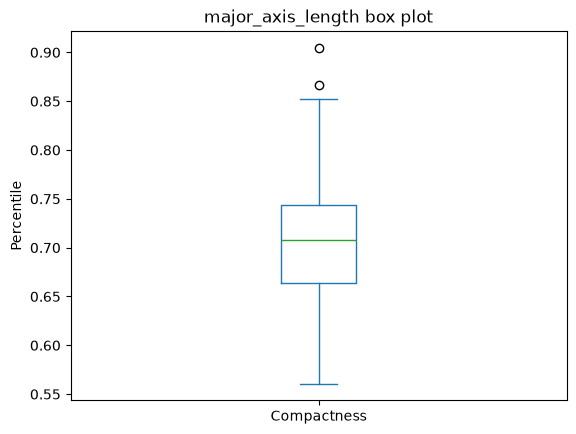

In [342]:
# Task 3
df_pumpkin["Compactness"].plot.box(title="major_axis_length box plot", ylabel="Percentile")

print(f"""
IQR seems to lie within 0.65-0.75 range with some outliers above the upper quartile. 
Most datapoints seem to be located within the IQR, but the data varies a lot by size as seen by the long whiskers.
The median is {df_pumpkin["Major_Axis_Length"].median()} and seems to be slightly skewed towards the upper quartile.
""")


Most pumpkins seem to have an area between 65000-105000 and the amount datapoints larger than 105000 drop off rapidly.
The datapoints before 65000 have around 200 entries, but it is little compared to the about 1800 in the range 65000-105000.



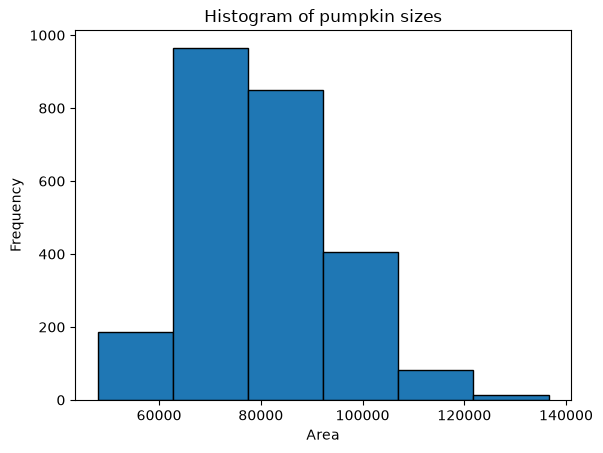

In [343]:
# Task 3
df_pumpkin["Area"].plot.hist(
    edgecolor="black",
    bins=6,
    xlabel="Area",
    title="Histogram of pumpkin sizes")
print(f"""
Most pumpkins seem to have an area between 65000-105000 and the amount datapoints larger than 105000 drop off rapidly.
The datapoints before 65000 have around 200 entries, but it is little compared to the about 1800 in the range 65000-105000.
""")


The classes seem to roughly balanced between each other, but class 0 has a slightly higher count.



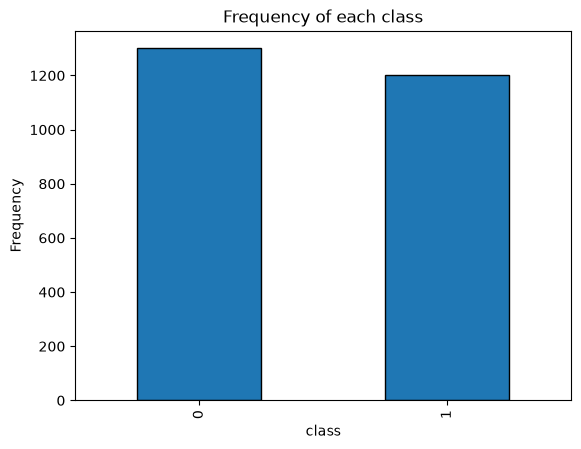

In [344]:
# Task 3
df_pumpkin["class"].value_counts().plot.bar(
    edgecolor="black",
    title="Frequency of each class",
    ylabel="Frequency")


print(f"""
The classes seem to roughly balanced between each other, but class 0 has a slightly higher count.
""")

In [345]:
# Task 4
print("""
Based on the EDA it would be beneficial to scale the data as many of the features operate on different scales. 
Extent and compactness operate on ratios near 1, and the other features like area are many times larger.
""")


Based on the EDA it would be beneficial to scale the data as many of the features operate on different scales. 
Extent and compactness operate on ratios near 1, and the other features like area are many times larger.




None of features are linearly separable. Major axis length vs area plot shows the most separation while extent vs area shows the most overlap.
All featrues seem to be related in some way.



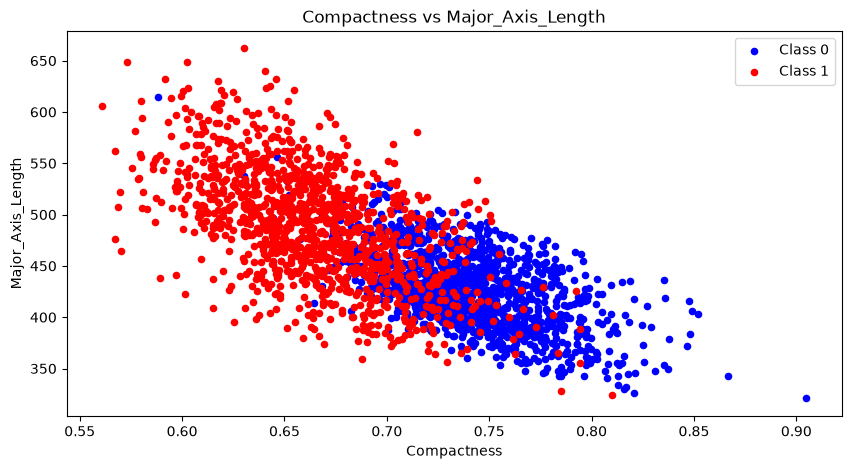

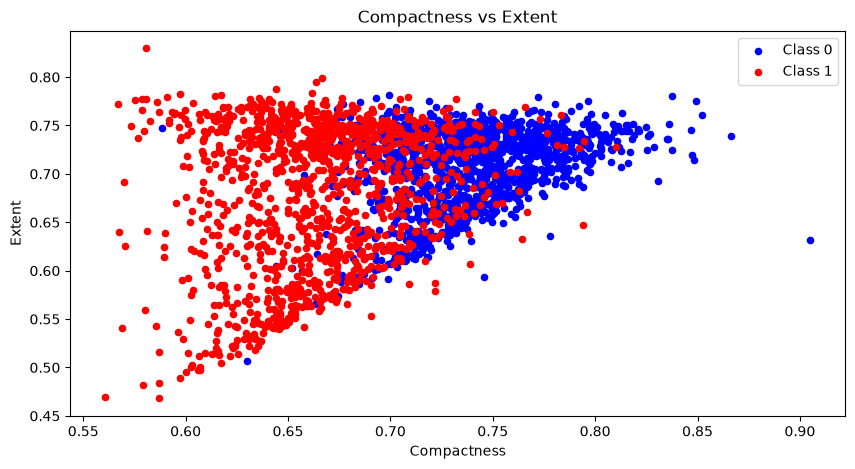

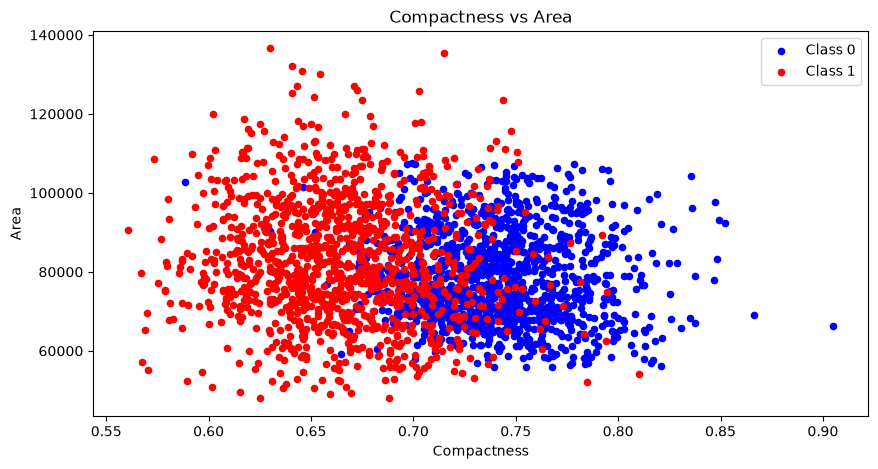

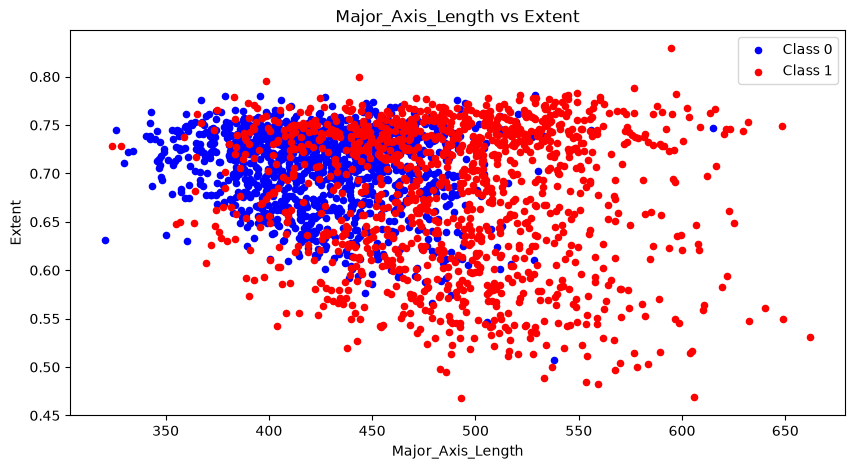

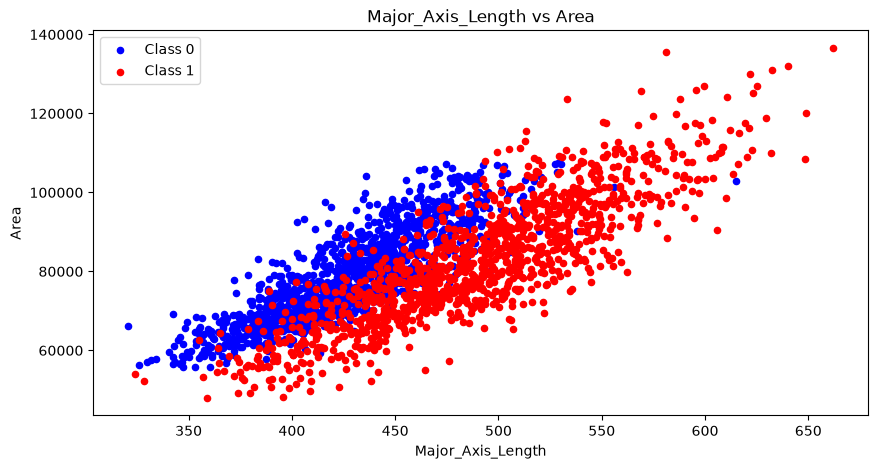

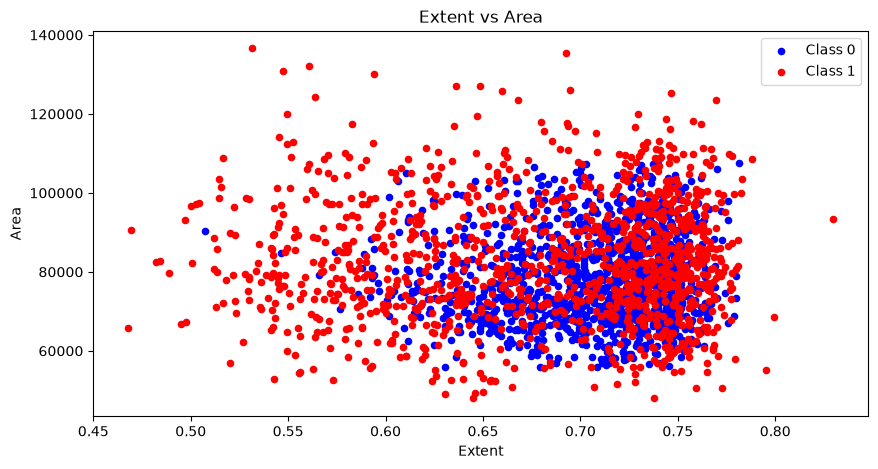

In [346]:
# Task 5
print(f"""
None of features are linearly separable. Major axis length vs area plot shows the most separation while extent vs area shows the most overlap.
All featrues seem to be related in some way.
""")

# Finds all combinations of features to plot except class
plot_combos = list(combinations(df_pumpkin.columns[:-1], 2))

for combo in plot_combos:
    fig, ax = plt.subplots(figsize=(10, 5))
    df_pumpkin.loc[df_pumpkin["class"] == 0].plot.scatter(ax=ax, x=combo[0], y=combo[1], color="blue", label="Class 0")
    df_pumpkin.loc[df_pumpkin["class"] == 1].plot.scatter(ax=ax, x=combo[0], y=combo[1], color="red", label="Class 1")
    ax.legend()
    ax.set_title(f"{combo[0]} vs {combo[1]}")
    plt.show()

## Part II: Train/Test Split

Divide your dataset into training and testing subsets. Follow these steps to create the split:

1. **Divide the dataset into two data sets, each containing samples of only one class:**
   - Create a DataFrame `df_0` containing all samples with `"class"` equal to `0`.
   - Create a DataFrame `df_1` containing all samples with `"class"` equal to `1`.

2. **Split into training and test sets by randomly sampling entries from the data frames:**
   - Create a DataFrame `df_0_train` by sampling `75%` of the entries from `df_0` (use the `sample` method with `random_state=42`).
   - Create a DataFrame `df_1_train` using the same approach with `df_1`.
   - Create a DataFrame `df_0_test` containing the remaining entries of `df_0` (use `df_0.drop(df_0_train.index)`).
   - Create a DataFrame `df_1_test` using the same approach with `df_1`.

3. **Merge the datasets split by classes back together:**
   - Create a DataFrame `df_train` containing all entries from `df_0_train` and `df_1_train` (use the `concat` method).
   - Create a DataFrame `df_test` containing all entries from the two test sets.

4. **Create the following data frames from these splits:**
   - `X_train`: contains all columns of `df_train` except for the target feature `"class"`
   - `X_test`: contains all columns of `df_test` except for the target feature `"class"`
   - `Y_train`: contains only the target feature `"class"` for all samples in the training set
   - `Y_test`: contains only the target feature `"class"` for all samples in the test set

5. **Check that your sets have the expected sizes/shape by printing the number of rows and columns (`shape`) of the data sets.**
   - (Sanity check: there should be **4 features**, and the training set should contain roughly **75%** of the total samples, with the test set containing the remaining **25%**.)

6. **Explain the purpose of this slightly complicated procedure.**
   - Why did we first split into the two classes?
   - Why did we then split into a training and a testing set?

7. **What is the share (in percent) of samples with class `0` in the test set, training set, and in the initial data set?**


In [347]:
# Part II sec 1-4
df_0 = df_pumpkin.loc[df_pumpkin["class"] == 0]
df_1 = df_pumpkin.loc[df_pumpkin["class"] == 1]

df_0_train = df_0.sample(random_state=42, frac=0.75)
df_1_train = df_1.sample(random_state=42, frac=0.75)

df_0_test = df_0.drop(df_0_train.index)
df_1_test = df_1.drop(df_1_train.index)

df_train = pd.concat([df_0_train, df_1_train])
df_test = pd.concat([df_0_test, df_1_test])

X_train = df_train.drop(columns="class")
X_test = df_test.drop(columns="class")

Y_train = df_train.drop(columns=df_train.columns[:-1])
Y_test = df_test.drop(columns=df_test.columns[:-1])

# Part II sec 5
original_shape = df_pumpkin.shape
print(f"""
X_test features: {X_test.shape[1]}
X_test percent of samples {X_test.shape[0]/original_shape[0]*100}%
X_train features: {X_train.shape[1]}
X_train percent of samples {X_train.shape[0]/original_shape[0]*100}%

Y_test features: {Y_test.shape[1]}
Y_test percent of samples {Y_test.shape[0]/original_shape[0]*100}%
Y_train features: {Y_train.shape[1]}
Y_train percent of samples {Y_train.shape[0]/original_shape[0]*100}%
""")

# Part II sec 6
print(f"""
The classes are split into two to avoid a skewed ratio of classes in the test and train datasets. 
When testing our model unseen data is needed to avoid overfitting.
""")

# Part II sec 7
print(f"""
Percent of class 0 in test set {X_test.loc[df_pumpkin["class"] == 0].shape[0]/original_shape[0]*100}%
Percent of class 0 in training set {X_train.loc[df_pumpkin["class"] == 0].shape[0]/original_shape[0]*100}%
Percent of class 0 in inital set {df_pumpkin.loc[df_pumpkin["class"] == 0].shape[0]/original_shape[0]*100}%
""")



X_test features: 4
X_test percent of samples 25.0%
X_train features: 4
X_train percent of samples 75.0%

Y_test features: 1
Y_test percent of samples 25.0%
Y_train features: 1
Y_train percent of samples 75.0%


The classes are split into two to avoid a skewed ratio of classes in the test and train datasets. 
When testing our model unseen data is needed to avoid overfitting.


Percent of class 0 in test set 13.0%
Percent of class 0 in training set 39.0%
Percent of class 0 in inital set 52.0%



### Convert data to numpy arrays and shuffle the training data

Many machine learning models (including those you will use later in this assignment) do not accept `pandas` DataFrames as input. Instead, they require the data to be provided as raw `numpy` arrays.  
In this step, convert the DataFrames `X_train`, `X_test`, `Y_train`, and `Y_test` into the corresponding numpy arrays with the same variable names.

In addition, shuffle the training data. This is necessary because the training set is currently ordered by class (all samples of class 0 followed by all samples of class 1).  
In Part IV, the classifiers will be trained using the **first _n_ samples** of the training set. If the data were not shuffled, the models would initially be trained only on samples from a single class, which would lead to biased learning and unreliable performance.

Nothing to be done here, just execute the cell.


In [348]:
# convert to numpy arrays
X_train = X_train.to_numpy()
X_test = X_test.to_numpy()
Y_train = Y_train.to_numpy()
Y_test = Y_test.to_numpy()

# shuffle training data
np.random.seed(42) # for reproducibility
shuffle_index = np.random.permutation(len(X_train)) # generate random indices
X_train, Y_train = X_train[shuffle_index], Y_train[shuffle_index] # shuffle data by applying reordering with the random indices

## Part III: Scaling the data

1. Standardize the training _and_ test data so that each feature has a mean of 0 and a standard deviation of 1.
2. Check that the scaling was successful
   - by printing the mean and standard deviation of each feature in the scaled training set
   - by putting the scaled training set into a DataFrame and making a violin plot of the data

__Hint:__ use the `axis` argument to calculate mean and standard deviation column-wise.

__Important:__ Avoid data leakage!  
Compute the mean and standard deviation only on the training data, and then apply the same transformation to both the training and test sets.

__More hints:__

1. For each column, subtract the training mean $(\mu_{\text{train}})$ from each value in that column  
2. Divide the result by the training standard deviation $(\sigma_{\text{train}})$

Mathematically, this transformation for each column is:

$$ X_{\text{scaled}} = \frac{X - \mu_{\text{train}}}{\sigma_{\text{train}}}$$

where:
- $X_{\text{scaled}}$ are the transformed column values (a column vector)  
- $X$ is the original column  
- $\mu_{\text{train}}$ is the mean of the column computed on the training set  
- $\sigma_{\text{train}}$ is the standard deviation of the column computed on the training set  


Compactness mean: 0.70
Compactness std: 0.05

Major_Axis_Length mean: 455.79
Major_Axis_Length std: 56.21

Extent mean: 0.69
Extent std: 0.06

Area mean: 80511.42
Area std: 13732.61



[Text(0, 0.5, 'Standardized value'),
 Text(0.5, 1.0, 'Violinplot of pumpkin features after scaling')]

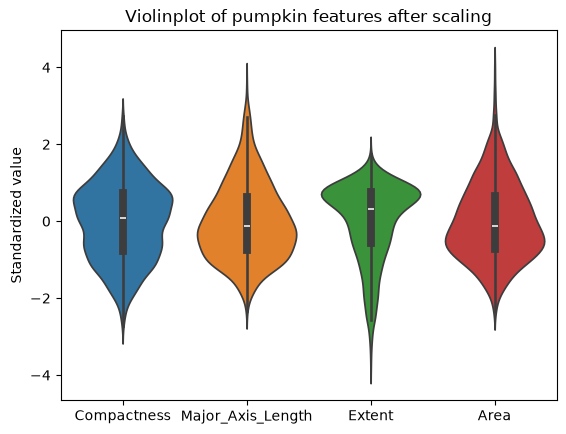

In [ ]:
column_names = df_pumpkin.columns

for idx in range(X_train.shape[1]):
    train_mean = np.mean(X_train[:, idx])
    train_std = np.std(X_train[:, idx])

    X_train[:, idx] = (X_train[:, idx]-train_mean)/train_std
    X_test[:, idx] = (X_test[:, idx]-train_mean)/train_std

    print(f"{column_names[idx]} mean: {abs(train_mean):.2f}")
    print(f"{column_names[idx]} std: {train_std:.2f}\n")

scaled_df = pd.DataFrame(X_train)
scaled_df.columns = column_names[:-1]
ax = sns.violinplot(
    scaled_df
    )
ax.set(ylabel="Standardized value", title="Violinplot of pumpkin features after scaling")


## Part IV: Training and evaluation with different dataset sizes and training times

Often, a larger dataset size will yield better model performance. (As we will learn later, this usually prevents overfitting and increases the generalization capability of the trained model.)
However, collecting data is usually rather expensive.

In this part of the exercise, you will investigate

- how the model performance changes with varying dataset size
- how the model performance changes with varying numbers of epochs/iterations of the optimizer/solver (increasing training time).

For this task (Part IV), use the `Adaline`, `Perceptron`, and `LogisticRegression` classifiers from the `mlxtend` library. All use the gradient descent (GD) algorithm for training.

__Important__: Use a learning rate of `1e-5` (`0.00001`) for all classifiers, and use the argument `minibatches=1` when initializing the `Adaline` and `LogisticRegression` classifiers (this will make sure they use GD). For all three classifiers, pass `random_seed=42` when initializing the classifier to ensure reproducibility of the results.

### Model training

Train the models using progressively larger subsets of your dataset, specifically: first 50 rows, first 100 rows, first 150 rows, ..., first 650 rows, first 700 rows (in total $14$ different variants).

For each number of rows train the model with progressively larger number of epochs: 2, 7, 12, 17, ..., 87, 92, 97 (in total $20$ different model variants).

This will result in $14 \times 20 = 280$ models obtained from the different combinations of subsets and number of epochs. An output of the training process could look like this:

```
Model (1) Train a model with first 50 rows of data for 2 epochs
Model (2) Train a model with first 50 rows of data for 7 epochs
Model (3) Train a model with first 50 rows of data for 12 epochs
...
Model (21) Train a model with first 100 rows of data for 2 epochs
Model (22) Train a model with first 100 rows of data for 7 epochs
...
Model (279) Train a model with first 700 rows of data for 92 epochs
Model (280) Train a model with first 700 rows of data for 97 epochs
```

### Model evaluation

For each of the $280$ models, calculate the __accuracy on the test set__ (do __not__ use the score method but compute accuracy yourself).
Store the results in the provided 2D numpy array (it has $14$ rows and $20$ columns).
The rows of the array correspond to the different dataset sizes, and the columns correspond to the different numbers of epochs.

### Tasks
1. Train the $280$ Adaline classifiers as mentioned above and calculate the accuracy for each of the $280$ variants.
2. Generalize your code so that it is doing the same procedure for all three classifiers: `Perceptron`, `Adaline`, and `LogisticRegression` after each other. Store the result for all classifiers. You can for example use an array of shape $3\times14\times20$ to store the accuracies of the three classifiers.

Note that executing the cells will take some time (but on most systems it should not be more than 5 minutes).


In [369]:
learning_rate=1e-5
# Mini batches: 1
# Seed: 42

# First slice [n] is classifier, 0 is adaline, 1 is perceptron, 3 is logistic_regression
# Second slice [n][m] are all values from specific amount of rows
# Third slice [n][m][k] is a singular result from a amount of rows and epochs

scores = np.zeros((3, 14, 20))
Y_test_flattend = Y_test.flatten()
ada = mc.Adaline(eta=learning_rate, minibatches=1, random_seed=42)
percept = mc.Perceptron(eta=learning_rate, random_seed=42)
reg = mc.LogisticRegression(eta=learning_rate, minibatches=1, random_seed=42)

for classifier in range(3):
    for idx_rows, rows in enumerate(range(50, 700+1, 50)):
        for idx_epochs, epochs in enumerate(range(2, 97+1, 5)):
            if classifier == 0:
                ada.epochs = epochs
                ada.fit(X_train[:rows, :], Y_train[:rows, :].flatten())
                predictions = ada.predict(X_test[:rows, :])
                scores[classifier][idx_rows][idx_epochs] = (len(np.where(predictions==Y_test_flattend[:rows])[0]))/predictions.shape[0]

            elif classifier == 1:
                percept.epochs = epochs
                percept.fit(X_train[:rows, :], Y_train[:rows, :].flatten())
                predictions = percept.predict(X_test[:rows, :])
                scores[classifier][idx_rows][idx_epochs] = (len(np.where(predictions==Y_test_flattend[:rows])[0]))/predictions.shape[0]

            elif classifier == 2:
                reg.epochs = epochs
                reg.fit(X_train[:rows, :], Y_train[:rows, :].flatten())
                predictions = reg.predict(X_test[:rows, :])
                scores[classifier][idx_rows][idx_epochs] = (len(np.where(predictions==Y_test_flattend[:rows])[0]))/predictions.shape[0]

### Performance visualization

Plot the performance measure for all classifiers (accuracy on the test set; use the result array from above) of all the $280$ variants for each classifier in a total of three heatmaps using, for example `seaborn` or `matplotlib` directly.

The color should represent the accuracy on the test set, and the x and y axes should represent the number of epochs and the dataset size, respectively.
Which one is x and which one is y is up to you to decide. Look in the example output at the top of the assignment for inspiration for how the plot could look like and how it could be labeled nicely. (But use the correct numbers corresponding to your dataset sizes and number of epochs.)


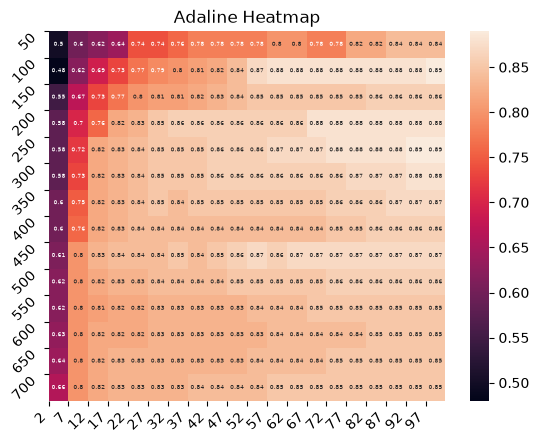

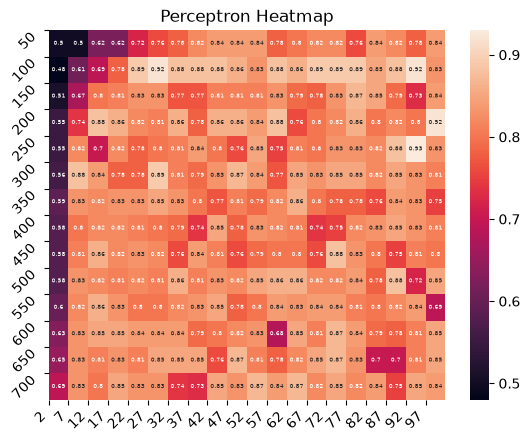

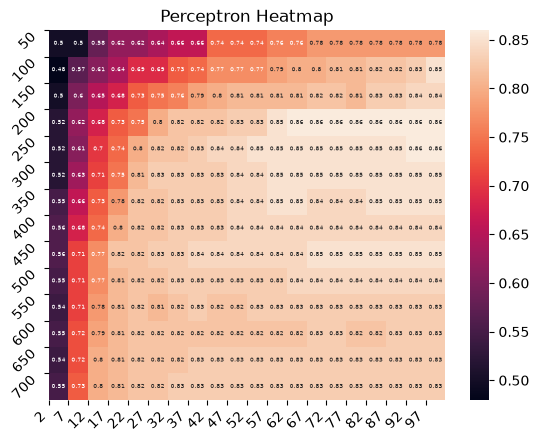

In [409]:
row_increments = range(50, 700+1, 50)
epoch_increments = range(2, 97+1, 5)

df_scores_ada = pd.DataFrame(np.round(scores[0], 2))
df_scores_percept = pd.DataFrame(np.round(scores[1], 2))
df_scores_reg = pd.DataFrame(np.round(scores[2], 2))

fig_ada, ax_ada = plt.subplots()
sns.heatmap(df_scores_ada, ax=ax_ada, annot=True, annot_kws={"size": 4})
ax_ada.set(title="Adaline Heatmap")
ax_ada.set_xticks(range(len(epoch_increments)), labels=epoch_increments, rotation=45, rotation_mode="xtick")
ax_ada.set_yticks(range(len(row_increments)), labels=row_increments, rotation=45, rotation_mode="ytick")

fig_percept, ax_percept = plt.subplots()
sns.heatmap(df_scores_percept, ax=ax_percept, annot=True, annot_kws={"size": 4})
ax_percept.set(title="Perceptron Heatmap")
ax_percept.set_xticks(range(len(epoch_increments)), labels=epoch_increments, rotation=45, rotation_mode="xtick")
ax_percept.set_yticks(range(len(row_increments)), labels=row_increments, rotation=45, rotation_mode="ytick")

fig_reg, ax_reg = plt.subplots()
sns.heatmap(df_scores_reg, ax=ax_reg, annot=True, annot_kws={"size": 4})
ax_reg.set(title="Perceptron Heatmap")
ax_reg.set_xticks(range(len(epoch_increments)), labels=epoch_increments, rotation=45, rotation_mode="xtick")
ax_reg.set_yticks(range(len(row_increments)), labels=row_increments, rotation=45, rotation_mode="ytick")

plt.show()


# Part V: Some more plotting
For the following cell to execute you need to have the variables `X_train_scaled` and `y_train` (to train the model) as well as `X_test_scaled` and `y_test` (to plot the test samples).
Complete at least up until Part III. Executing the cell will plot something.

This dataset has 4 features, so the plot will be a 4×4 grid showing pairwise feature decision regions.


1. Add code comments explaining what the lines are doing
2. What is the purpose of the plot?
    The purpose of the plots is to show how if it is possible to cleanly separate the two classes.
3. Describe all components of the subplot and then comment in general on the entire plot. What does it show? What does it not show?
    The colored background represents the probability of a class 1. 
    The black line marks the decision boundary.
    Class 0 is the triangle
    Class 1 is the circles

    It dosent capture how all features relate together


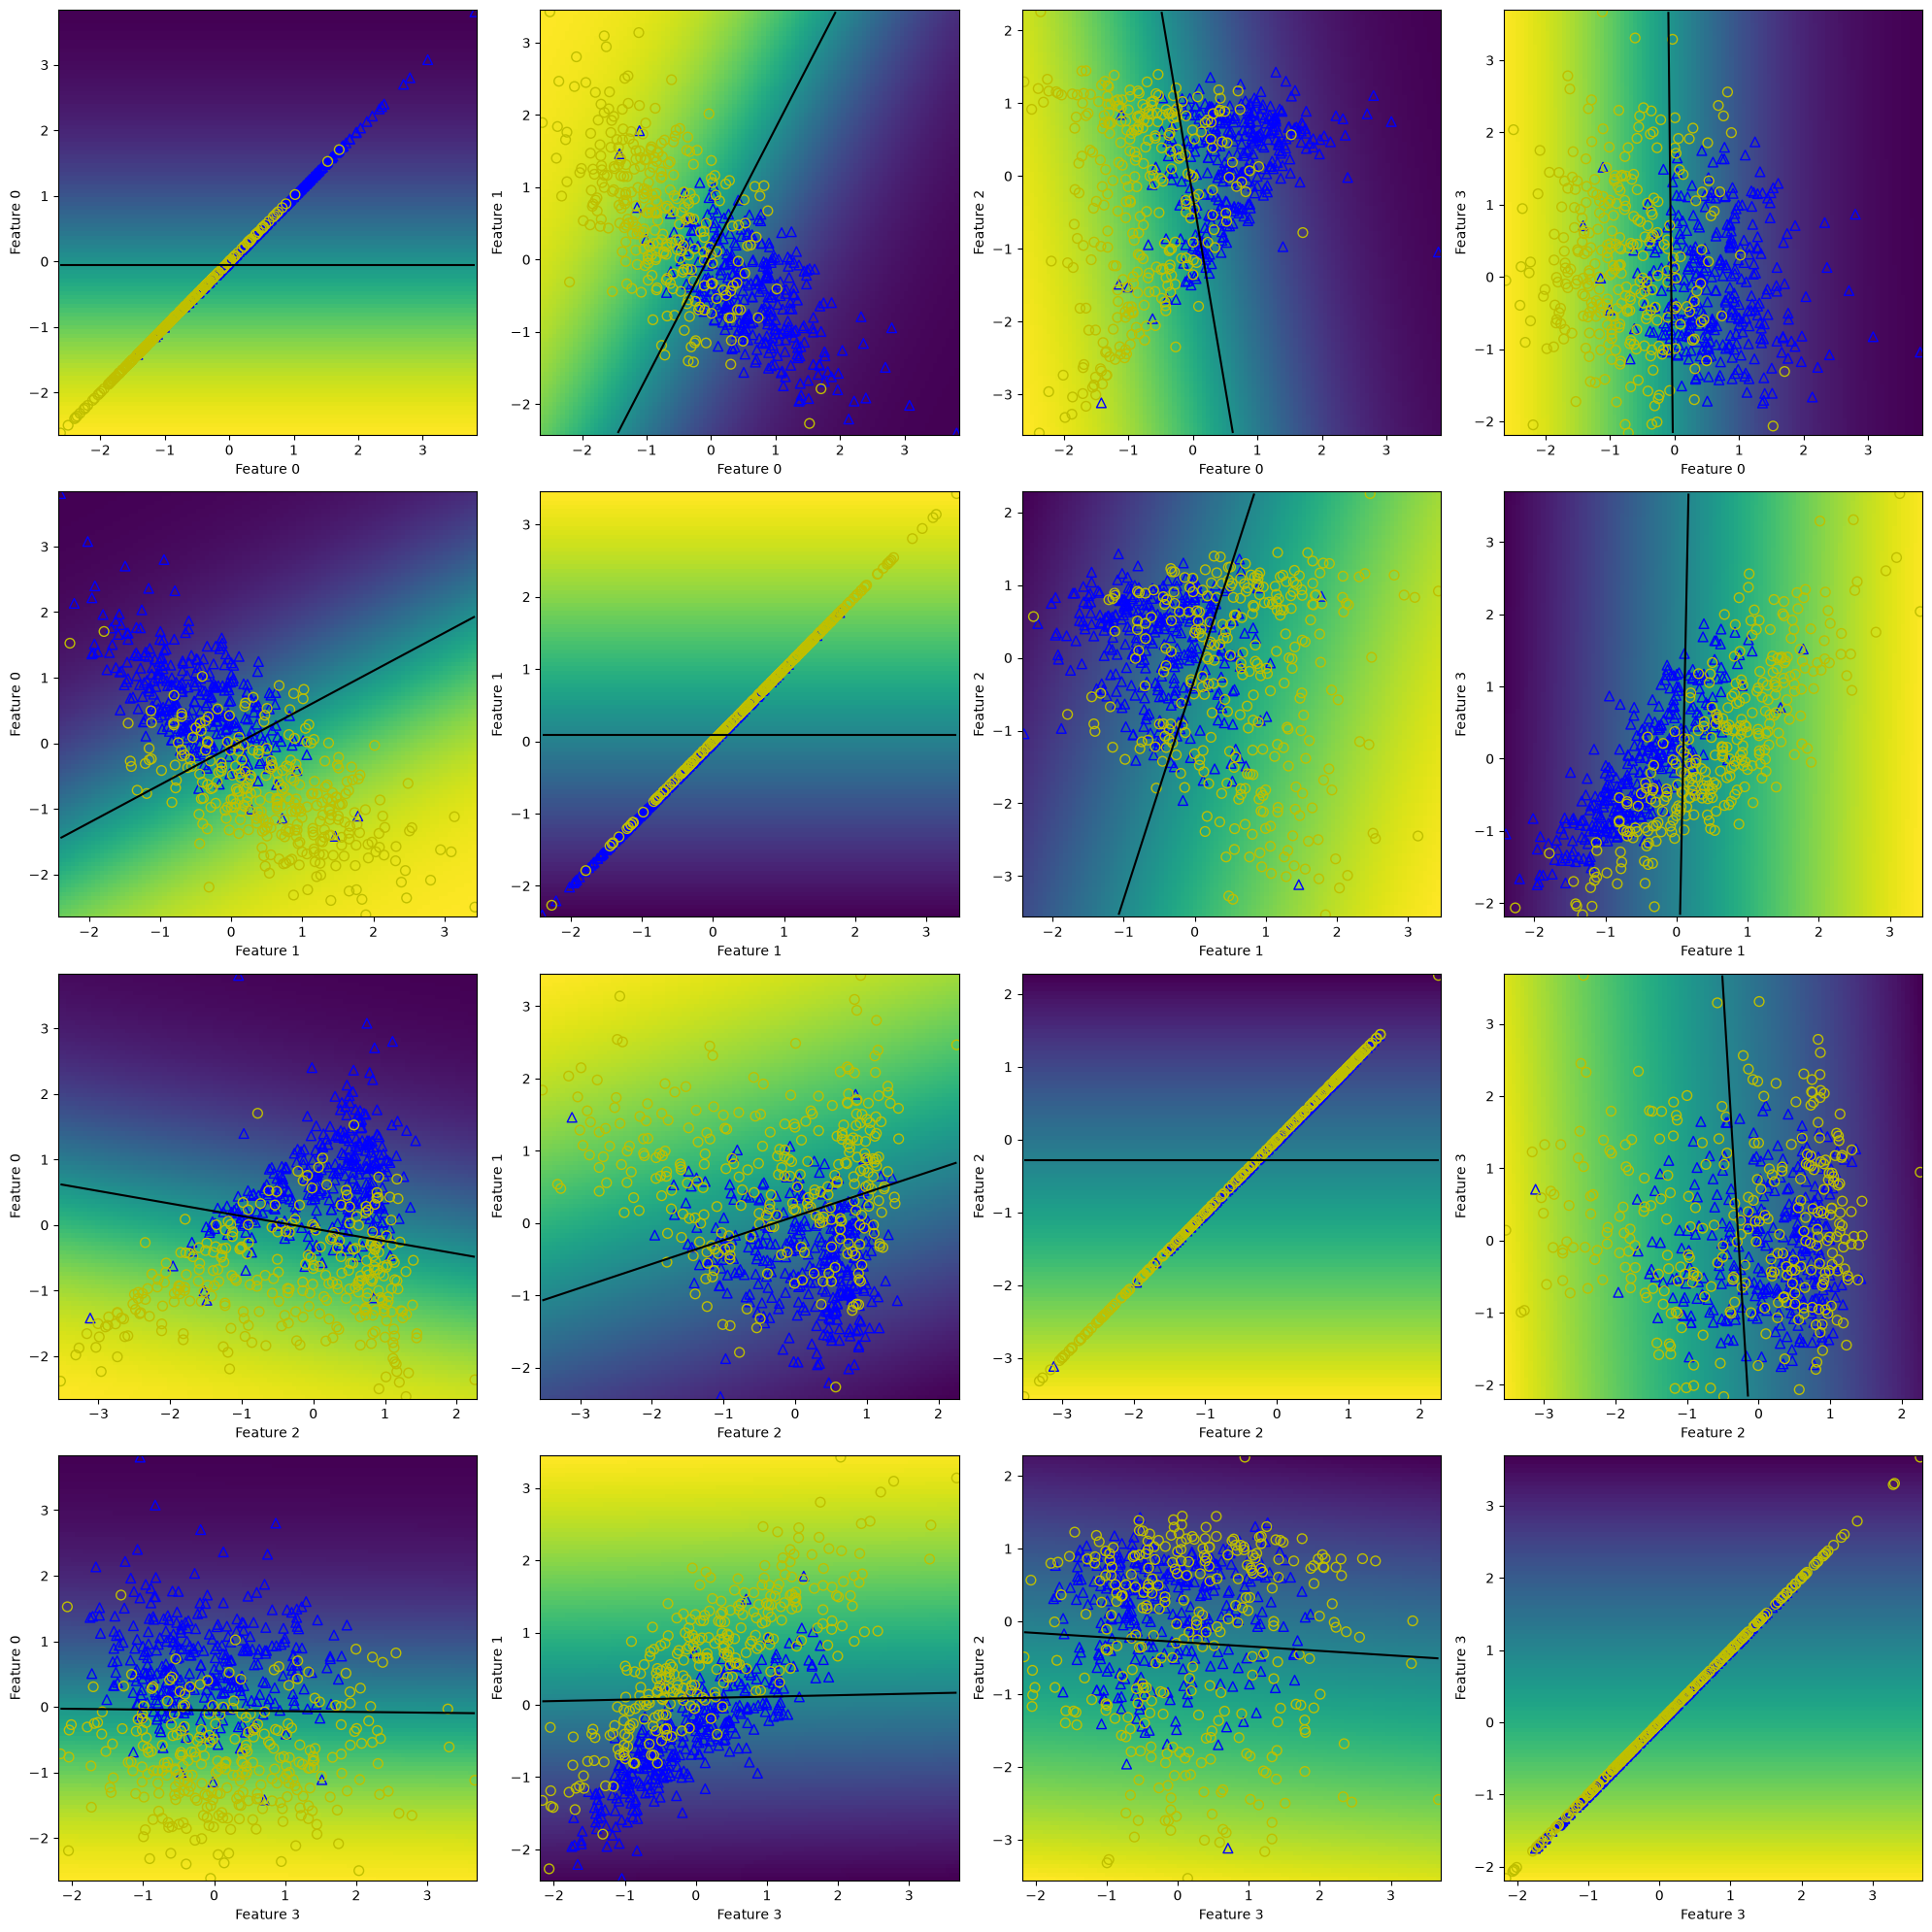

In [ ]:
# Perform logistic regression on the full dataset
clf = mc.LogisticRegression(eta=1e-5, epochs=300, minibatches=1, random_seed=42)
clf.fit(X_train, Y_train.flatten())

n_features = X_test.shape[1]

# Create the figure
fig, axes = plt.subplots(n_features, n_features, figsize=(5*n_features, 5*n_features))

mins = X_test.min(axis=0)
maxs = X_test.max(axis=0)

# Plot all features in from the dataset in subplots
for i in range(n_features):
    for j in range(n_features):

        feature_1 = i
        feature_2 = j
        ax = axes[i, j]

        ax.set_xlabel(f"Feature {feature_1}")
        ax.set_ylabel(f"Feature {feature_2}")

        # Create grid for the two selected features
        x0 = np.linspace(mins[feature_1], maxs[feature_1], 100)
        x1 = np.linspace(mins[feature_2], maxs[feature_2], 100)

        X0, X1 = np.meshgrid(x0, x1)

        # Create full feature matrix with other features set to 0
        X_plot = np.zeros((X0.size, n_features))
        X_plot[:, feature_1] = X0.ravel()
        X_plot[:, feature_2] = X1.ravel()

        # Predict probability of class 1
        y_pred = clf.predict_proba(X_plot)
        Z = y_pred.reshape(X0.shape)

        # Plot probability surface
        ax.pcolor(X0, X1, Z, shading="auto")

        # Plot decision boundary (p = 0.5)
        ax.contour(X0, X1, Z, levels=[0.5], colors="k")

        # Plot test samples
        ax.scatter(
            X_test[Y_test.flatten() == 0, feature_1],
            X_test[Y_test.flatten() == 0, feature_2],
            color="b", marker="^", s=50, facecolors="none"
        )

        ax.scatter(
            X_test[Y_test.flatten() == 1, feature_1],
            X_test[Y_test.flatten() == 1, feature_2],
            color="y", marker="o", s=50, facecolors="none"
        )

fig.tight_layout()
plt.show()

## Part VI: Additional discussion

### Part I:
1. What kind of plots did you use to visualize the raw data, and why did you choose these types of plots?<br>
    Boxplot, easy to spot outliers how spread the data is. <br>
    Barplot, easy to compare to different values<br>
    Violinplot, easy to check if scaled values are correct<br>
    Heatmap, easy visualiation of different how good each parameter performed<br>
    Scatter, used in to find in classes are linearly separable<br>

### Part II:
1. What happens if we don't shuffle the training data before training the classifiers like in Part IV?<br>
    All class 0 come first and class 1 comes last which means first 50 rows dont have an instance of both classes<br>
2. How could you do the same train/test split (Point 1.-4.) using scikit-learn?<br>
    X_train, X_test, Y_train, Y_test = train_test_split(<br>
        X, Y,<br>
        test_size=0.25,<br>
        random_state=42,<br>
        stratify=y)<br>


### Part IV:
1. How does increasing the dataset size affect the performance of the logistic regression model? Provide a summary of your findings.<br>
    More data reduced the score of the reg model while around 200 datapoints performed best. Epochs seemed to generally improve the model.<br>
2. Describe the relationship between the number of epochs and the model accuracy.<br>
    Epochs seemed to generally improve the model.<br>
3. Which classifier is much slower to train and why do you think that is?<br>
    Logistic regression is slower to train, because of the higher computation power required<br>
4. One classifier shows strong fluctuations in accuracy for different dataset sizes and number of epochs. Which one is it and why do you think this happens?<br>
    Perceptron only converges if the data is linearly separable, and the data is not.<br>
